# Inference efficiency

Forward-only inference with synthetic inputs already on the selected device.
No training or checkpoint download is required for this architecture benchmark.
Results are saved after each model/batch combination in a timestamped directory.
Charts contain only axes and model labels; error bars span repeat-average timings.


In [4]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import platform
import sys

repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root / "src"))

import pandas as pd
import torch
from IPython.display import Image, display
from models import get_classification_model
from benchmark import benchmark_inference
from utils.io import save_inference_results
from visualization import plot_inference_results

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
BATCH_SIZES = (1, 32)
IMAGE_SIZE = (224, 224)
NUM_ITERATIONS = 100
WARMUP_ITERATIONS = 50
REPEATS = 5
PRETRAINED = False
NUM_CLASSES = 37
DTYPE = torch.float32
SEED = 42
MODEL_NAMES = {
    "ConvNeXt Tiny": ("convnext_tiny", "convnext_tiny"),
    "Swin Transformer Tiny": ("swin_tiny", "swin_tiny_patch4_window7_224"),
    "ResNet-50": ("resnet50", "resnet50"),
}
OUTPUT_DIR = repo_root / "results" / "efficiency" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
print(f"Device: {DEVICE} | Results: {OUTPUT_DIR}")


Device: mps | Results: /Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/efficiency/20261026T211958029409Z


In [5]:
torch.manual_seed(SEED)
metadata = {
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "hardware": torch.cuda.get_device_name() if DEVICE == "cuda" else platform.processor() or platform.machine(),
    "versions": {name: version(name) for name in ("torch", "torchvision", "timm")},
    "cpu_threads": torch.get_num_threads(),
    "seed": SEED,
}
results = []
for model_name, (model_id, timm_name) in MODEL_NAMES.items():
    model = get_classification_model(timm_name, pretrained=PRETRAINED, num_classes=NUM_CLASSES).to(dtype=DTYPE)
    for batch_size in BATCH_SIZES:
        inputs = torch.randn(batch_size, 3, *IMAGE_SIZE, device=DEVICE, dtype=DTYPE)
        result = benchmark_inference(model, inputs, DEVICE, NUM_ITERATIONS, WARMUP_ITERATIONS, REPEATS)
        results.append({"model_name": model_name, "model_id": model_id, "timm_model": timm_name, **result})
        saved = save_inference_results(results, OUTPUT_DIR, metadata)
        print(f"{model_name}, batch size {batch_size}: {result['batch_latency_ms']:.3f} ms/batch, "
              f"{result['throughput_images_per_second']:.1f} images/s")
        del inputs
    model.to("cpu")
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


ConvNeXt Tiny, batch size 1: 2.919 ms/batch, 342.6 images/s
ConvNeXt Tiny, batch size 32: 81.839 ms/batch, 391.0 images/s
Swin Transformer Tiny, batch size 1: 3.992 ms/batch, 250.5 images/s
Swin Transformer Tiny, batch size 32: 100.902 ms/batch, 317.1 images/s
ResNet-50, batch size 1: 3.555 ms/batch, 281.3 images/s
ResNet-50, batch size 32: 68.658 ms/batch, 466.1 images/s


,model_name,model_id,timm_model,device,dtype,batch_size,num_iterations,warmup_iterations,repeats,batch_latency_ms,batch_latency_min_ms,batch_latency_max_ms,throughput_images_per_second,throughput_min_images_per_second,throughput_max_images_per_second,flops_per_batch,gflops_per_image,parameters
0,ConvNeXt Tiny,convnext_tiny,convnext_tiny,mps,torch.float32,1,100,50,5,2.918962,2.903867,2.938420,342.587526,340.318947,344.368428,8909583360,8.909583,27848581
1,ConvNeXt Tiny,convnext_tiny,convnext_tiny,mps,torch.float32,32,100,50,5,81.839288,81.713712,82.340603,391.010243,388.629652,391.611141,285106667520,8.909583,27848581
2,Swin Transformer Tiny,swin_tiny,swin_tiny_patch4_window7_224,mps,torch.float32,1,100,50,5,3.992392,3.960645,3.994645,250.476400,250.335162,252.484101,8979654144,8.979654,27547807
3,Swin Transformer Tiny,swin_tiny,swin_tiny_patch4_window7_224,mps,torch.float32,32,100,50,5,100.901589,100.740489,101.024582,317.140695,316.754589,317.647853,287348932608,8.979654,27547807
4,ResNet-50,resnet50,resnet50,mps,torch.float32,1,100,50,5,3.554720,3.537384,3.574077,281.316109,279.792511,282.694769,8174424064,8.174424,23583845
5,ResNet-50,resnet50,resnet50,mps,torch.float32,32,100,50,5,68.658195,68.604295,69.168458,466.076916,462.638618,466.443097,261581570048,8.174424,23583845


inference_batch_1.png


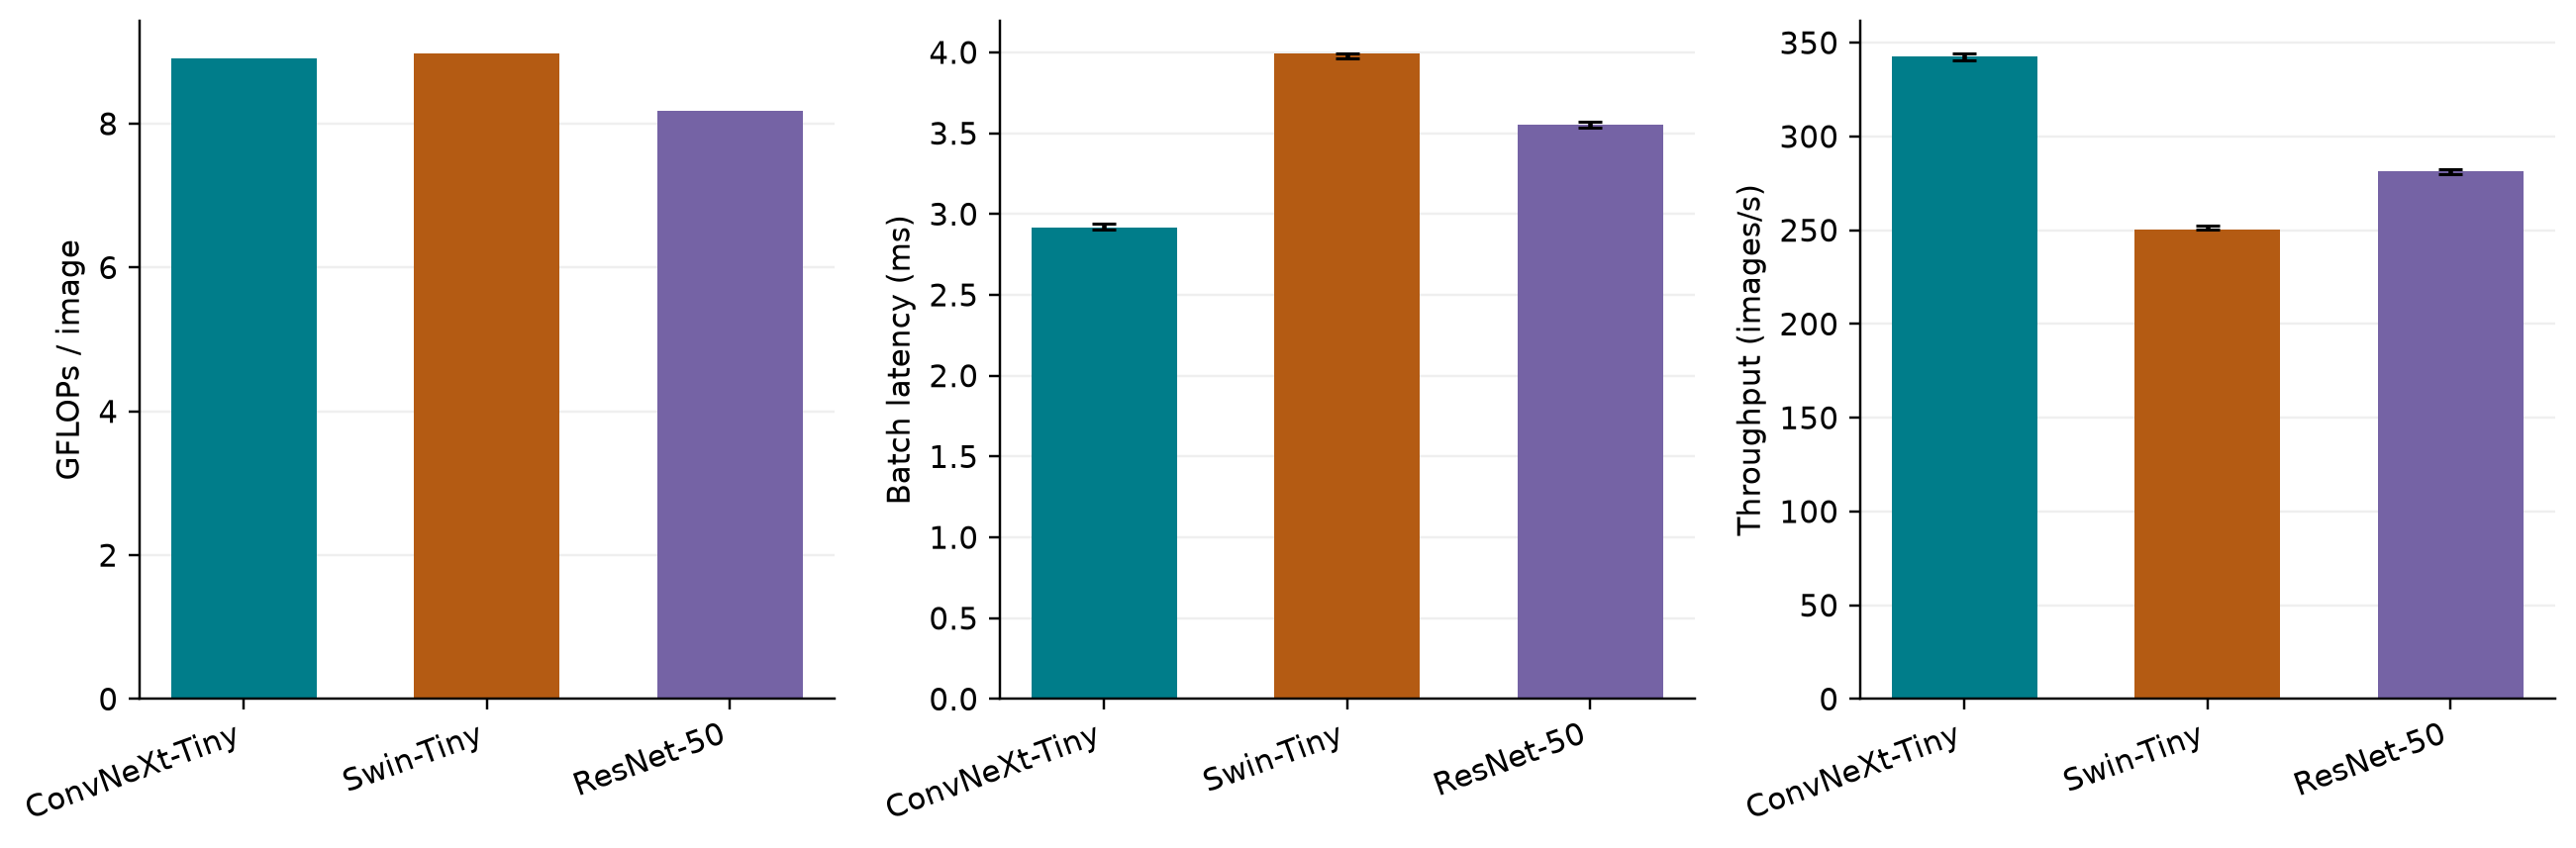

inference_batch_32.png


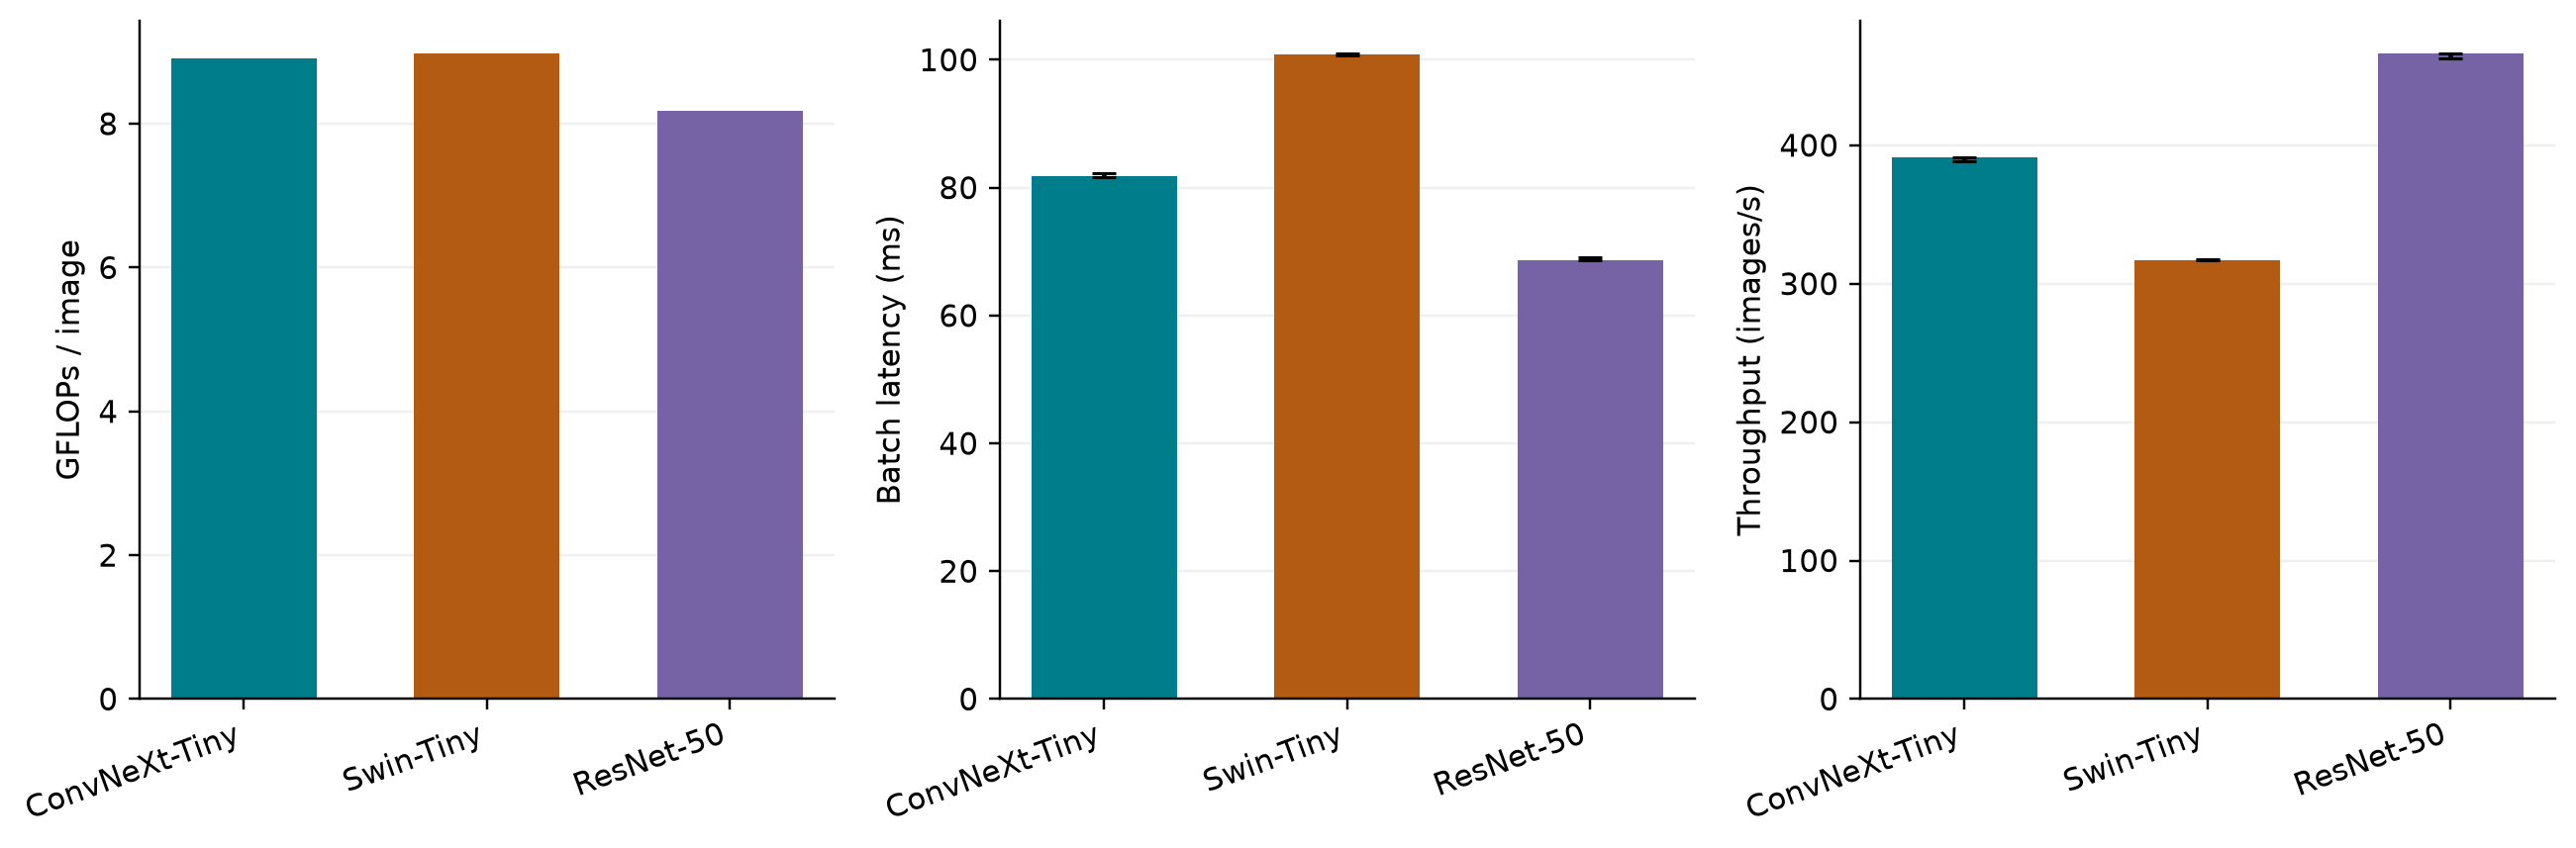

Saved: {'json': PosixPath('/Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/efficiency/20261026T211958029409Z/inference_results.json'), 'csv': PosixPath('/Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/efficiency/20261026T211958029409Z/inference_summary.csv')}


In [6]:
display(pd.read_csv(OUTPUT_DIR / "inference_summary.csv"))
for path in plot_inference_results(results, OUTPUT_DIR):
    print(path.name)
    display(Image(filename=str(path)))
print("Saved:", saved)
